# 제품 트레이스와 자율성 진단

이 절은 남이 공개한 실행 기록 자료를 읽습니다.
공개 저장소 두 곳의 원본 파일에서 옮긴 단계 차례와, 제품 문서 셋에서 옮긴 단서입니다.
단계 차례에서 보이는 것과 보이지 않는 것을 가르고, 자율성 진단표를 채웁니다.

**이 노트북에서 할 일**

1. 공개 단계 차례 두 건을 읽고 차례·결과·실패 뒤 다음 한 일을 봅니다.
2. 자료에 없는 칸을 가리고, 그 칸을 채워 01절 규칙에 넣으면 어떻게 되는지 봅니다.
3. 제품 문서 단서에서 그 일을 정하는 쪽이 어떻게 적혔는지 셉니다.
4. 자율성 진단표에 이 챕터 환불 문의 흐름의 답과 근거를 적습니다.

**준비물** — 이 절은 모델을 부르지 않습니다.
공개된 자료를 읽는 절이라 API 키가 필요 없고, 모델 요청은 0번이며 드는 비용도 없습니다.
읽는 자료 파일은 실습 폴더 `data/`의 넷이고, 새로 쓰는 파일은 없습니다.
자료 속 제품과 에이전트는 이 노트북에서 다시 실행하지 않습니다.
교재 출력을 만든 실행에서는 노트북 전체가 1초 안에 끝났습니다.

**기준 버전** — 파이썬에 들어 있는 기능만 써서 설치할 패키지가 없습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
공개 단계 차례를 읽고, 자료에 없는 칸을 가리는 자리입니다.
7·8절 제품 문서 단서와 진단표, 9·10절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 초록 상자 공개 추출본 두 건 SWE-agent mini-SWE-agent에서 왼쪽 칸 자료에 있는 칸 넷으로 이어져 초록 상자 step action outcome evidence가 파란 상자 print_events print_after_failures를 지나 노란 상자 실패 뒤 다음 한 일 10 뒤 11 1 뒤 2 8 뒤 9에 닿고 오른쪽 칸 자료에 없는 칸에는 회색 상자 다음 단계를 고른 쪽 고른 까닭과 걸린 초 토큰 수와 01절 classify로 가를 수 없음 04절 대가를 잴 수 없음이 위에서 아래로 놓인 그림](attachment:05-1-보이는-칸과-보이지-않는-칸.png)

맨 위 초록 상자가 이 절이 읽는 공개 추출본 두 건입니다.
왼쪽 칸은 자료에 있는 칸 넷을 함수 둘로 읽어 얻은 값이고, 노란 상자가 노트북에서 출력한 실패 뒤 짝입니다.
오른쪽 칸의 회색 상자 셋은 자료에 없는 칸과, 그래서 할 수 없는 일입니다.
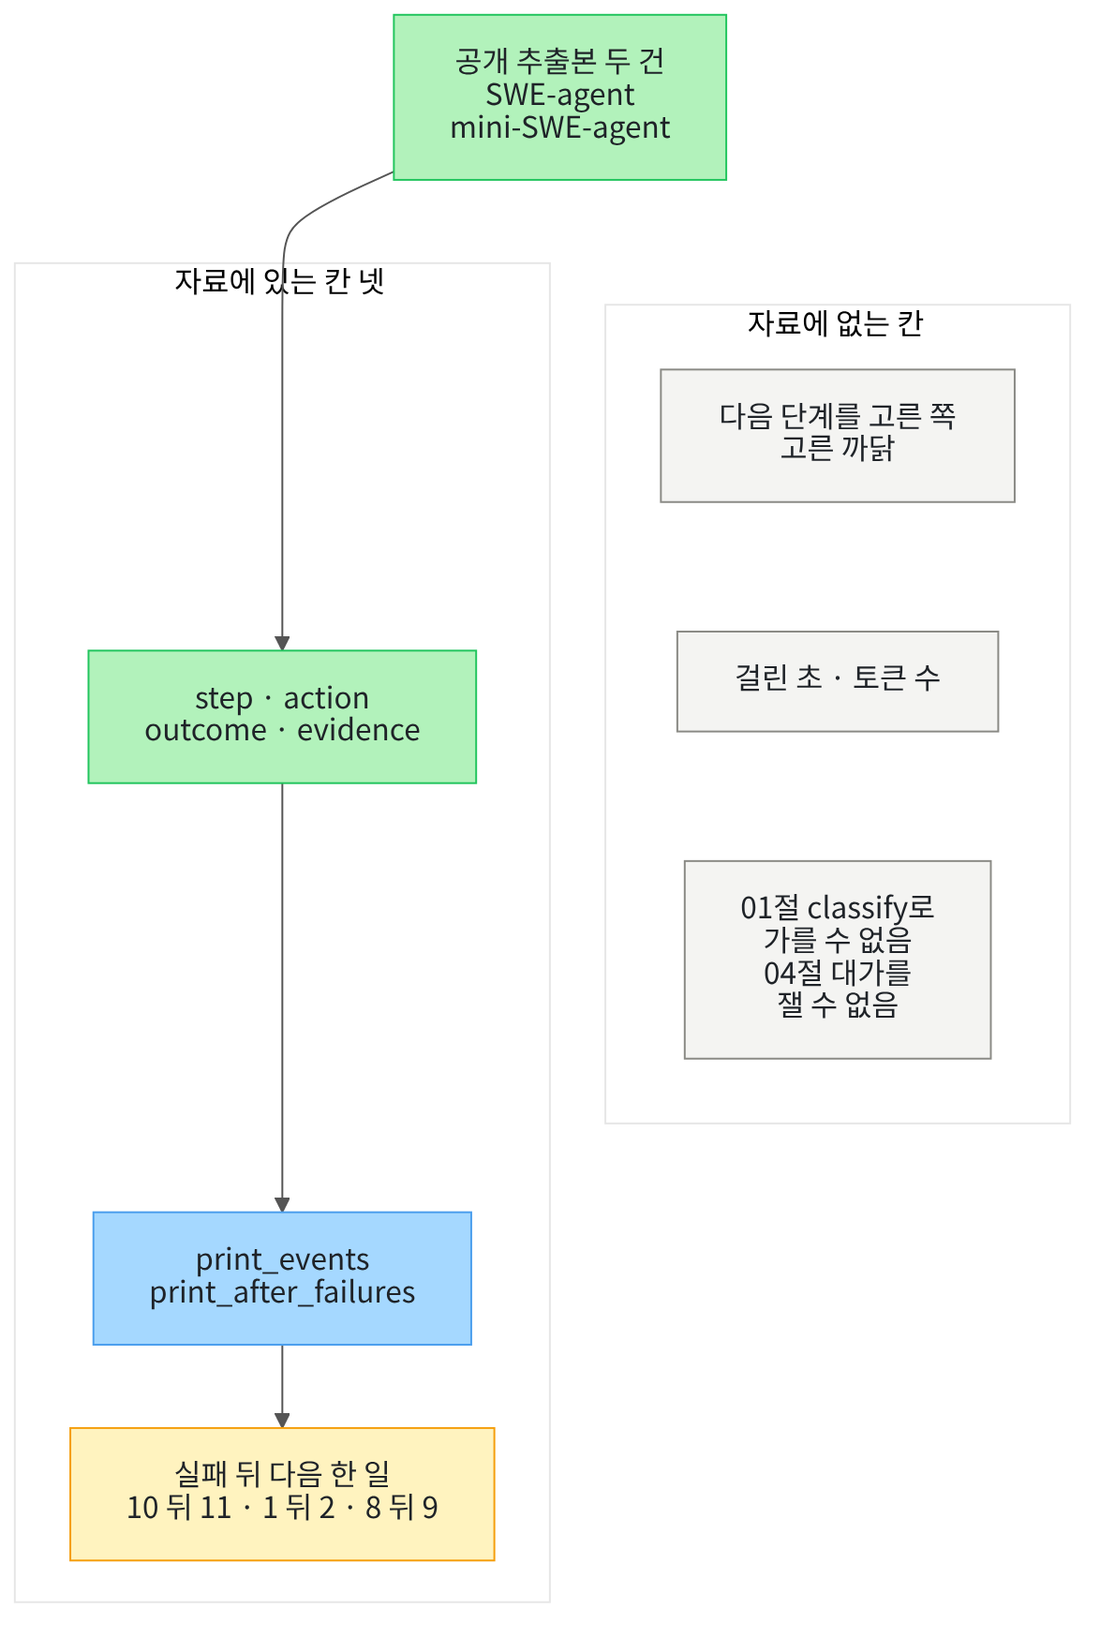

## 1. 준비

이 절은 파이썬에 들어 있는 기능만 씁니다.
첫 셀은 JSON 파일과 CSV 파일을 읽을 이름을 불러오고, 01절에서 배운 함수 둘을 가져옵니다.

앞에서 배운 함수는 `agent_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
가져오는 함수는 칸 값이 같은 줄을 세는 함수와, 구조를 가르는 함수입니다.

In [1]:
# 자료 파일을 읽을 이름과, 01절에서 배운 함수 둘을 도구 파일에서 가져옵니다
import csv
import json
import os
import sys

from agent_tools import classify, count_steps

python_version = sys.version.split()[0]
print("파이썬 판:", python_version)
print("가져온 함수:", "classify", "count_steps")

파이썬 판: 3.12.13
가져온 함수: classify count_steps


**결과 읽기** — 출력 줄 `파이썬 판: 3.12.13`과 `가져온 함수: classify count_steps`가 보입니다.
두 함수는 01절 노트북에서 정의한 함수와 같은 본문입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 자료 파일이 있는 프로젝트 맨 위 폴더를 찾습니다.
노트북은 보통 `notebooks/` 폴더에서 열리고, 도구 파일을 가져오려면 이 자리여야 합니다.
후보 세 곳은 실행 도구가 다른 자리에서 시작할 때를 위한 것입니다.

그래서 후보를 차례로 보고, 자료 폴더가 있는 첫 자리에서 `break`로 멈춥니다.
함수 `os.path.exists`는 그 자리에 폴더나 파일이 있으면 `True`를 내놓습니다.
비교 `is not None`은 변수에 값이 들어 있는지 보는 비교입니다.

In [2]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch17-agent-overview/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
data_folder = root_path + "/labs/part5/ch17-agent-overview/data"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
변수 `data_folder`에 자료 폴더 자리를 담았고, 아래 셀들이 이 자리에서 파일을 읽습니다.

## 2. 공개 단계 차례 자료

04절에서 단계 차례는 실행 기록에 적힌 단계를 일어난 차례대로 늘어놓은 것이라고 했습니다.
이 절의 첫 자료 파일은 남이 공개한 단계 차례 두 건을 담습니다.
두 건 모두 공개 저장소의 원본 파일에서 필요한 칸만 차례를 지켜 옮긴 추출본입니다.

다음 셀은 JSON 파일을 읽는 함수입니다.
파일은 `with open(…, encoding="utf-8")`로 열고, 안의 글을 `read()`로 읽습니다.
그 글을 Ch 15 02절처럼 `json.loads`로 파이썬 값으로 바꿉니다.
인코딩을 적지 않으면 컴퓨터마다 다른 기본 인코딩으로 읽혀 한국어가 깨질 수 있습니다.

In [3]:
# 파일 자리를 받아 UTF-8로 열고, 안의 JSON 글을 파이썬 값으로 바꿔 내놓습니다
def read_json(path):
    with open(path, encoding="utf-8") as json_file:
        text = json_file.read()
    return json.loads(text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `read_json`은 파일 자리 하나를 받아 파이썬 값 하나를 내놓습니다.
`with` 블록이 끝나면 파일은 저절로 닫힙니다.

다음 셀은 공개 단계 차례 자료를 읽고 자료마다 이름을 봅니다.

In [4]:
# 공개 단계 차례 자료 파일을 읽고 자료마다 이름을 봅니다
traces = read_json(data_folder + "/public-trace-extracts.json")
print("자료 수:", len(traces))
for trace in traces:
    print("자료 이름:", trace["product"])

자료 수: 2
자료 이름: SWE-agent v0.7.0 demonstration
자료 이름: mini-SWE-agent GitHub issue fixture


**결과 읽기** — 출력 줄 `자료 수: 2`로 자료 두 건이 목록에 들어 있습니다.
첫 이름 `SWE-agent v0.7.0 demonstration`은 SWE-agent 0.7.0 판의 시범 기록(demonstration)이라는 뜻입니다.
둘째 이름 `mini-SWE-agent GitHub issue fixture`는 테스트에 쓰려고 저장해 둔 파일(fixture)이라는 뜻입니다.
두 이름 모두 자료에 적힌 말 그대로입니다.

다음 셀은 자료마다 원본 파일이 어디에 있는지 봅니다.
커밋(commit)은 Ch 3에서 배운 대로 저장소의 한 시점을 가리키는 이름입니다.
지문은 Ch 7 08절에서처럼 파일 내용으로 만든 SHA-256 값이고, 한 글자만 달라도 바뀝니다.

In [5]:
# 자료마다 원본 파일이 있는 저장소·커밋·라이선스와 원본 파일의 지문을 봅니다
print("저장소 | 커밋 앞 일곱 자리 | 라이선스 | 지문 앞 열두 자리")
for trace in traces:
    commit = trace["commit"][:7]
    fingerprint = trace["sha256"][:12]
    print(trace["repository"], "|", commit, "|", trace["license"], "|", fingerprint)

저장소 | 커밋 앞 일곱 자리 | 라이선스 | 지문 앞 열두 자리
SWE-agent/SWE-agent | 3ea751c | MIT | 8856076ec318
SWE-agent/mini-swe-agent | 04d809c | MIT | 86d060a4881e


**결과 읽기** — 라벨 줄 아래 두 줄이 자료 두 건의 원본 자리입니다.
출력 줄 `SWE-agent/SWE-agent | 3ea751c | MIT | 8856076ec318`이 첫 자료입니다.
둘째 줄 `SWE-agent/mini-swe-agent | 04d809c | MIT | 86d060a4881e`도 라이선스가 MIT입니다.
MIT 라이선스는 저작권 표시를 남기면 복사·수정·배포를 허락하는 공개 라이선스입니다.
자료에는 원본 파일의 주소와 전체 지문도 함께 적혀 있습니다.

## 3. SWE-agent 시범 기록 읽기

첫 자료의 SWE-agent는 언어 모델이 명령을 하나씩 써서 저장소의 결함을 고치게 하는 공개 도구입니다.
이 자료는 그 도구의 시범 기록에서 단계를 옮긴 추출본입니다.
단계 한 줄은 칸 넷을 가진 딕셔너리이고, 칸 이름은 자료에 적힌 영어 그대로입니다.
칸 `step`은 번호, `action`은 한 일, `outcome`은 결과, `evidence`는 결과를 보여 준 근거 글입니다.

다음 셀은 단계 목록을 받아 칸 넷을 한 줄씩 출력하는 함수입니다.
01절 함수 `print_steps`처럼 라벨 줄을 먼저 출력합니다.

In [6]:
# 단계마다 번호·한 일·결과·근거를 한 줄씩 출력합니다(칸 이름은 자료에 적힌 영어 칸)
def print_events(events):
    print("번호 | 한 일 | 결과 | 근거")
    for event in events:
        print(event["step"], "|", event["action"], "|", event["outcome"], "|", event["evidence"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_events`는 단계 목록 하나를 받아 줄마다 번호·한 일·결과·근거를 출력합니다.
자료에 적힌 영어 칸 이름을 그대로 쓰므로 두 자료 모두에 쓸 수 있습니다.

다음 셀은 첫 자료를 꺼내 자료 모양과 단계 수를 보고, 단계 차례를 출력합니다.

In [7]:
# 첫 자료(SWE-agent 시범 기록)를 꺼내 자료 모양과 단계 수를 보고 단계 차례를 출력합니다
swe_trace = traces[0]
swe_events = swe_trace["events"]
print("자료 모양:", swe_trace["artifact_format"])
print("단계 수:", len(swe_events))
print_events(swe_events)

자료 모양: SWE-agent .traj JSON; action-observation turns
단계 수: 14
번호 | 한 일 | 결과 | 근거
1 | ls | success | repository listing
2 | open setup.py | success | 94-line file opened
3 | install dev dependencies | success | editable install output
4 | create reproduction | success | reproduce.py created
5 | write reproduction | success | 9-line script
6 | run reproduction | success | observed 344
7 | list files | success | reproduce.py present
8 | find fields.py | success | one match
9 | open target lines | success | TimeDelta serialization lines
10 | edit without indentation | failure | E999 IndentationError; edit rejected
11 | edit with indentation | success | file updated
12 | rerun reproduction | success | observed 345
13 | remove reproduction | success | temporary file removed
14 | submit patch | success | exit_status submitted; one-line patch


**결과 읽기** — 출력 줄 `단계 수: 14`로 단계 열넷이 들어 있습니다.
라벨 줄 아래 열네 줄을 번호 차례대로 읽으면 이 기록의 단계 차례입니다.
출력 줄 `6 | run reproduction | success | observed 344`에서 결함을 다시 만드는 글을 실행해 344를 보았습니다.
출력 줄 `10 | edit without indentation | failure | E999 IndentationError; edit rejected`만 결과가 실패입니다.
출력 줄 `12 | rerun reproduction | success | observed 345`에서 같은 글을 다시 실행하자 345가 나왔습니다.

한 일의 이름과 근거는 자료에 적힌 영어 그대로입니다.
자료에 적힌 말 `edit without indentation`은 들여쓰기 없이 파일을 고쳐 쓴 일입니다.
근거의 `edit rejected`는 도구가 그 고쳐 쓰기를 받아들이지 않았다는 뜻입니다.
자료 모양 칸의 `action-observation turns`는 한 일과 그 결과(관찰)가 번갈아 적힌 모양이라는 뜻입니다.

다음 셀은 01절 함수 `count_steps`로 결과별 단계 수를 셉니다.
이 함수는 칸 이름을 인자로 받으므로 자료의 영어 칸 `outcome`에도 그대로 씁니다.

In [8]:
# 01절 함수 count_steps에 자료의 영어 칸 이름 outcome을 넣어 결과별 단계 수를 셉니다
print("결과가 success인 단계:", count_steps(swe_events, "outcome", "success"))
print("결과가 failure인 단계:", count_steps(swe_events, "outcome", "failure"))

결과가 success인 단계: 13
결과가 failure인 단계: 1


**결과 읽기** — 출력 줄 `결과가 success인 단계: 13`과 `결과가 failure인 단계: 1`이 보입니다.
두 수를 더하면 단계 수와 같아, 결과가 둘 가운데 하나로 적혀 있습니다.
01절 함수를 고치지 않고 영어 칸 자료에 그대로 썼습니다.

## 4. 실패 뒤 다음 한 일

단계 차례에서 먼저 볼 자리는 실패한 단계의 바로 다음입니다.
그 자리에서 한 일이 바뀌었다면, 실패를 본 뒤 다음 한 일을 새로 정했다는 뜻입니다.
다음 셀은 결과가 `failure`인 단계를 찾아, 그 단계와 바로 다음 단계의 한 일을 나란히 출력하는 함수입니다.
마지막 단계에는 다음 단계가 없으므로 번호 `i`는 끝에서 하나 앞까지만 돕니다.

In [9]:
# 결과가 failure인 단계마다 그 번호·한 일과 바로 다음 단계의 한 일을 출력합니다
def print_after_failures(events):
    print("실패한 번호 | 실패한 일 | 다음 한 일")
    last = len(events) - 1
    for i in range(last):
        event = events[i]
        if event["outcome"] == "failure":
            print(event["step"], "|", event["action"], "|", events[i + 1]["action"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_after_failures`는 라벨 줄과, 실패한 단계마다 한 줄을 출력합니다.
실패한 단계가 없으면 라벨 줄만 나옵니다.

다음 셀은 SWE-agent 자료에 이 함수를 씁니다.

In [10]:
# SWE-agent 자료에서 실패한 단계와 바로 다음 단계의 한 일을 봅니다
print_after_failures(swe_events)

실패한 번호 | 실패한 일 | 다음 한 일
10 | edit without indentation | edit with indentation


**결과 읽기** — 라벨 줄 아래 한 줄 `10 | edit without indentation | edit with indentation`이 보입니다.
들여쓰기 없이 고쳐 쓰다 실패한 바로 다음 단계에서, 들여쓰기를 넣어 다시 고쳐 썼습니다.
실패 뒤 한 일이 바뀐 자리는 단계 차례만 보고도 찾을 수 있습니다.
그러나 바뀐 한 일을 누가 골랐는지는 이 출력에 없습니다.

다음 셀은 자료를 만든 사람이 따로 적어 둔 칸 셋을 봅니다.
실패 뒤 짝(`recovery_pairs`), 코드가 정한 경계(`hardcoded_boundary`), 해석의 한계(`interpretation_limit`)입니다.

In [11]:
# 자료를 만든 사람이 따로 적어 둔 실패 뒤 짝·코드가 정한 경계·해석의 한계를 봅니다
print("자료에 적힌 짝:", swe_trace["recovery_pairs"])
print("자료에 적힌 코드의 경계:", swe_trace["hardcoded_boundary"])
print("자료에 적힌 한계:", swe_trace["interpretation_limit"])

자료에 적힌 짝: [[10, 11, '편집 거부 뒤 들여쓰기를 고쳐 다시 편집']]
자료에 적힌 코드의 경계: 도구 문법 검사기가 들여쓰기 오류가 있는 편집을 거부하고 submit 도구가 종료를 표시합니다.
자료에 적힌 한계: 저장된 demonstration을 분석했으며 현재 버전의 SWE-agent를 다시 실행하지 않았습니다.


**결과 읽기** — 출력 줄 `자료에 적힌 짝: [[10, 11, '편집 거부 뒤 들여쓰기를 고쳐 다시 편집']]`은 4절 함수가 찾은 짝과 같은 10번과 11번입니다.
자료에 적힌 말 `편집 거부`는 도구가 고쳐 쓰기를 막았다는 뜻입니다.
자료에 적힌 코드의 경계는 도구의 문법 검사기가 들여쓰기 오류가 있는 고쳐 쓰기를 막았다는 내용입니다.
마지막 단계의 `submit` 도구가 끝을 표시한다는 것도 같은 줄에 적혀 있습니다.

모델이 무엇을 쓰든 코드가 먼저 막는 자리를 이 절에서는 코드가 정한 경계라고 부릅니다.
출력 줄 `자료에 적힌 한계:` 뒤 글은 저장된 시범 기록을 읽었을 뿐, 지금 판을 다시 실행하지 않았다는 뜻입니다.
이 노트북도 SWE-agent를 실행하지 않고 자료만 읽습니다.

## 5. mini-SWE-agent 테스트 파일 읽기

둘째 자료는 같은 SWE-agent 계정의 저장소 `mini-swe-agent`에서 가져왔습니다.
원본은 그 저장소가 테스트에 쓰려고 저장해 둔 파일입니다.
칸 이름과 모양이 첫 자료와 같아 같은 함수 `print_events`로 읽습니다.

In [12]:
# 둘째 자료(mini-SWE-agent 테스트 파일)를 꺼내 자료 모양과 단계 수를 보고 단계 차례를 출력합니다
mini_trace = traces[1]
mini_events = mini_trace["events"]
print("자료 모양:", mini_trace["artifact_format"])
print("단계 수:", len(mini_events))
print_events(mini_events)

자료 모양: mini-SWE-agent message trajectory; assistant command and user tool-result pairs
단계 수: 10
번호 | 한 일 | 결과 | 근거
1 | read absolute path | failure | returncode 1; file not found
2 | list repository | success | returncode 0
3 | list tests | success | returncode 0
4 | read target file | success | returncode 0; missing colon visible
5 | add missing colon | success | returncode 0
6 | read edited file | success | returncode 0
7 | run script | success | returncode 0; output 8.2
8 | run issue input | failure | returncode 1; ZeroDivisionError
9 | add zero check | success | returncode 0
10 | submit plus git diff | unconfirmed | diff is present but no returncode wrapper; completion status not verified


**결과 읽기** — 출력 줄 `단계 수: 10`으로 단계 열이 들어 있습니다.
출력 줄 `1 | read absolute path | failure | returncode 1; file not found`에서 첫 단계부터 실패했습니다.
출력 줄 `7 | run script | success | returncode 0; output 8.2`에서 고친 파일을 실행해 8.2를 보았습니다.
출력 줄 `8 | run issue input | failure | returncode 1; ZeroDivisionError`에서 다시 실패했습니다.
마지막 줄의 결과는 성공도 실패도 아닌 `unconfirmed`입니다.

근거 글의 `returncode`는 명령이 끝나며 남긴 종료 코드이고, 0이면 성공입니다.
자료에 적힌 말 `read absolute path`는 처음부터 적어 둔 파일 자리로 파일을 읽으려 한 일입니다.
오류 이름 `ZeroDivisionError`는 0으로 나눌 때 파이썬이 내는 오류입니다.
자료 모양 칸에는 명령이 `assistant` 역할 글에, 도구 결과가 `user` 역할 글에 적혔다고 되어 있습니다.
역할 이름 `assistant`는 채팅 요청에서 모델이 쓴 글에 붙는 이름입니다.

다음 셀은 결과별 단계 수를 세고, 4절 함수로 실패 뒤 다음 한 일을 봅니다.

In [13]:
# 결과별 단계 수를 세고, 실패한 단계 바로 다음의 한 일을 봅니다
print("결과가 success인 단계:", count_steps(mini_events, "outcome", "success"))
print("결과가 failure인 단계:", count_steps(mini_events, "outcome", "failure"))
print("결과가 unconfirmed인 단계:", count_steps(mini_events, "outcome", "unconfirmed"))
print_after_failures(mini_events)

결과가 success인 단계: 7
결과가 failure인 단계: 2
결과가 unconfirmed인 단계: 1
실패한 번호 | 실패한 일 | 다음 한 일
1 | read absolute path | list repository
8 | run issue input | add zero check


**결과 읽기** — 출력 줄 `결과가 success인 단계: 7`, `결과가 failure인 단계: 2`, `결과가 unconfirmed인 단계: 1`이 보입니다.
실패 뒤 짝은 두 줄입니다.
출력 줄 `1 | read absolute path | list repository`에서 파일을 못 찾자 다음 단계에서 저장소의 파일 목록을 보았습니다.
출력 줄 `8 | run issue input | add zero check`에서 0으로 나누다 실패하자 다음 단계에서 0인지 검사하는 줄을 더했습니다.

다음 셀은 결과가 `unconfirmed`인 마지막 단계와, 자료에 적힌 코드의 경계·한계를 봅니다.

In [14]:
# 마지막 단계의 결과·근거와, 자료에 적힌 코드의 경계·해석의 한계를 봅니다
last_event = mini_events[-1]
print("마지막 한 일:", last_event["action"], "|", last_event["outcome"])
print("마지막 근거:", last_event["evidence"])
print("자료에 적힌 코드의 경계:", mini_trace["hardcoded_boundary"])
print("자료에 적힌 한계:", mini_trace["interpretation_limit"])

마지막 한 일: submit plus git diff | unconfirmed
마지막 근거: diff is present but no returncode wrapper; completion status not verified
자료에 적힌 코드의 경계: 시스템 지시는 응답당 명령 하나와 단독 완료 명령을 요구하지만 마지막 행동은 완료 명령에 git 명령을 결합했습니다.
자료에 적힌 한계: 테스트 fixture를 분석했으며 패치의 요구 범위 적합성이나 외부 평가 통과는 확인하지 않았습니다.


**결과 읽기** — 출력 줄 `마지막 한 일: submit plus git diff | unconfirmed`가 보입니다.
마지막 근거는 바뀐 내용(diff)은 있지만 종료 코드를 남기지 않아 끝났는지 확인하지 못했다는 뜻입니다.
자료에 적힌 경계는 시스템 메시지로 준 지시가 끝낼 때는 끝내는 명령만 따로 쓰라고 했다는 내용입니다.
그런데 마지막 한 일은 끝내는 명령에 `git` 명령을 이어 붙였습니다.

SWE-agent 자료의 경계는 문법 검사기가 고쳐 쓰기를 실제로 막았습니다.
이 자료의 경계는 모델에게 글로 준 지시라서, 지시를 어긴 명령의 결과도 기록에 남았습니다.
코드가 막는 경계와 글로만 부탁한 규칙은 이렇게 다릅니다.

## 6. 단계 차례만으로 알 수 없는 것

지금까지 본 것은 차례와 한 일, 결과, 근거 글입니다.
01절부터 쓴 기록에는 칸 「고른 쪽」이 있었고, 04절은 칸 「걸린 초」·「입력 토큰」·「출력 토큰」을 더했습니다.
공개 자료에는 어떤 칸이 있는지 코드로 모아 봅니다.
다음 셀은 기록의 모든 줄을 돌며 칸 이름을 한 번씩만 모으는 함수입니다.
딕셔너리를 `for`로 돌면 칸 이름이 하나씩 나오고, `not in`으로 아직 없는 이름만 더합니다.

In [15]:
# 기록의 모든 줄을 돌며 칸 이름을 처음 나온 차례대로 한 번씩만 모읍니다
def key_names(events):
    names = []
    for event in events:
        for key in event:
            if key not in names:
                names.append(key)
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `key_names`는 칸 이름 목록 하나를 내놓습니다.
목록 안의 차례는 칸 이름이 처음 나온 차례입니다.

다음 셀은 두 자료의 칸 이름을 모아 견줍니다.

In [16]:
# 두 자료의 단계 한 줄에 어떤 칸이 있는지 모아 견줍니다
swe_keys = key_names(swe_events)
mini_keys = key_names(mini_events)
print("SWE-agent 자료의 칸:", swe_keys)
print("mini-SWE-agent 자료의 칸:", mini_keys)
print("두 자료의 칸이 같은가:", swe_keys == mini_keys)

SWE-agent 자료의 칸: ['step', 'action', 'outcome', 'evidence']
mini-SWE-agent 자료의 칸: ['step', 'action', 'outcome', 'evidence']
두 자료의 칸이 같은가: True


**결과 읽기** — 출력 줄 `SWE-agent 자료의 칸: ['step', 'action', 'outcome', 'evidence']`가 보입니다.
출력 줄 `두 자료의 칸이 같은가: True`로 두 자료 모두 이 칸 넷뿐입니다.
칸 「고른 쪽」도, 걸린 초나 토큰 칸도 없습니다.
그래서 이 자료로는 01절처럼 고른 쪽을 셀 수 없고, 04절처럼 자율성의 대가를 잴 수도 없습니다.

다음 셀은 자료의 단계를 01절 기록 한 줄 모양으로 옮기는 함수입니다.
자료의 한 일은 모두 명령을 실행한 일이라 칸 「한 쪽」은 `도구`로 적습니다.
자료에 없는 칸 「고른 쪽」은 인자 `chooser`로 받은 값으로 채웁니다.

In [17]:
# 자료의 단계를 01절 기록 한 줄 모양으로 옮기고, 자료에 없는 칸 「고른 쪽」은 받은 값으로 채웁니다
def to_steps(events, chooser):
    steps = []
    for event in events:
        line = {"단계": event["action"], "한 쪽": "도구", "고른 쪽": chooser}
        line["결과"] = event["outcome"]
        steps.append(line)
    return steps

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `to_steps`는 자료의 단계 목록과 채울 값을 받아 칸 넷짜리 기록 하나를 내놓습니다.
칸 「단계」에는 자료의 한 일이, 칸 「결과」에는 자료의 결과가 들어갑니다.

다음 셀은 모르는 칸을 「모름」으로 채워 옮기고, 01절 함수 `classify`로 가릅니다.

In [18]:
# 고른 쪽을 「모름」으로 채운 기록을 만들고 01절 함수로 셉니다
unknown_steps = to_steps(swe_events, "모름")
print("옮긴 첫 줄:", unknown_steps[0])
print("고른 쪽이 모름인 줄:", count_steps(unknown_steps, "고른 쪽", "모름"))
print("고른 쪽이 모델인 줄:", count_steps(unknown_steps, "고른 쪽", "모델"))
print("classify가 가른 구조:", classify(unknown_steps))

옮긴 첫 줄: {'단계': 'ls', '한 쪽': '도구', '고른 쪽': '모름', '결과': 'success'}
고른 쪽이 모름인 줄: 14
고른 쪽이 모델인 줄: 0
classify가 가른 구조: 워크플로우


**결과 읽기** — 출력 줄 `고른 쪽이 모름인 줄: 14`와 `고른 쪽이 모델인 줄: 0`이 보입니다.
그리고 출력 줄 `classify가 가른 구조: 워크플로우`가 나왔습니다.
함수 `classify`는 칸 「고른 쪽」이 모델인 줄이 없으면 워크플로우라고 가르기 때문입니다.
이 판정은 자료에서 나오지 않았고, 모르는 칸을 「모름」으로 채운 데서 나왔습니다.

01절 규칙은 칸 「고른 쪽」을 아는 기록에만 쓸 수 있습니다.
모르는 칸이 있는 기록에서는 판정 대신 모른다고 적습니다.
9절에서 같은 칸을 다른 값으로 채워 다시 가려 봅니다.

## 7. 제품 문서의 공개 추적 단서

둘째 자료 파일은 제품 셋의 공식 문서에서 옮긴 단서입니다.
공개 추적 단서는 제품 문서가 보여 준, 실행 기록에 남는 일의 종류와 그 일을 정하는 쪽입니다.
한 번의 실행에서 실제로 남은 기록은 아닙니다.
다음 셀은 이 파일을 읽고 제품마다 자료 종류와, 이 과정에서 실행했는지, 확인일을 봅니다.

In [19]:
# 제품 문서에서 옮긴 단서 자료를 읽고, 제품마다 자료 종류·이 과정에서 실행했는지·확인일을 봅니다
products = read_json(data_folder + "/product-trace-evidence.json")
print("제품 | 자료 종류 | 이 과정에서 실행 | 확인일")
for product in products:
    kind = product["artifact_type"]
    print(product["product"], "|", kind, "|", product["local_execution"], "|", product["checked"])

제품 | 자료 종류 | 이 과정에서 실행 | 확인일
OpenAI Codex | official_public_trace_signals | False | 2026-09-10
Anthropic Claude Code | official_public_trace_interface | False | 2026-09-10
OpenAI Deep Research | official_public_behavior_trace | False | 2026-09-10


**결과 읽기** — 라벨 줄 아래 세 줄이 제품 셋입니다.
출력 줄 `OpenAI Codex | official_public_trace_signals | False | 2026-09-10`처럼 셋 모두 셋째 칸이 `False`입니다.
자료의 칸 `local_execution`이 `False`이면 이 과정에서 그 제품을 실행하지 않았다는 뜻입니다.
확인일도 셋 모두 자료에 적힌 2026-09-10입니다.

단서 한 줄에는 칸 `event`(단서 이름)와 칸 `control`(그 일을 정하는 쪽)이 있습니다.
칸 `control`의 글은 자료를 만든 사람이 문서를 읽고 적은 한국어입니다.
다음 셀은 그 글에 어떤 낱말이 들어 있는 단서 수를 세는 함수입니다.
글에 `in`을 쓰면 낱말이 글 안 어디에든 들어 있는지 봅니다.

In [20]:
# 단서 목록에서 칸 control의 글에 낱말 word가 들어 있는 단서 수를 셉니다
def count_control(clues, word):
    count = 0
    for clue in clues:
        if word in clue["control"]:
            count = count + 1
    return count

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_control`은 단서 목록과 낱말 하나를 받아 수 하나를 내놓습니다.
01절 `count_steps`는 칸 값이 같은 줄을 세고, 이 함수는 낱말이 들어 있는 단서를 셉니다.

다음 셀은 제품마다 칸 `control`에 「모델」·「코드」·「미확인」이 적힌 단서 수를 셉니다.

In [21]:
# 제품마다 단서 수와, 칸 control에 모델·코드·미확인이 적힌 단서 수를 봅니다
print("제품 | 단서 수 | 모델 | 코드 | 미확인")
for product in products:
    clues = product["observable_events"]
    model_count = count_control(clues, "모델")
    code_count = count_control(clues, "코드")
    unknown_count = count_control(clues, "미확인")
    print(product["product"], "|", len(clues), "|", model_count, "|", code_count, "|", unknown_count)

제품 | 단서 수 | 모델 | 코드 | 미확인
OpenAI Codex | 3 | 0 | 1 | 2
Anthropic Claude Code | 4 | 0 | 4 | 0
OpenAI Deep Research | 5 | 5 | 0 | 0


**결과 읽기** — 라벨 줄 아래 세 줄을 견줍니다.
출력 줄 `OpenAI Deep Research | 5 | 5 | 0 | 0`은 칸 `control`에 「모델」이 든 단서가 다섯이라는 뜻입니다.
함수 `count_control`은 낱말이 들어 있는지만 보므로, 「제품 출력 요건과 모델 생성」처럼 적힌 단서도 모델로 셉니다.
출력 줄 `Anthropic Claude Code | 4 | 0 | 4 | 0`은 단서 넷 모두 코드가 정한다고 적혀 있습니다.
출력 줄 `OpenAI Codex | 3 | 0 | 1 | 2`는 단서 셋 가운데 둘이 미확인입니다.

이 차이는 세 제품의 자율성 차이가 아닙니다.
문서가 무엇을 설명하려고 쓴 글인지에 따라 드러난 쪽이 다릅니다.
자료의 한계 칸을 보면, 제품 Deep Research의 자료는 공식 설명에 나온 행동을 옮긴 것입니다.
제품 Claude Code의 자료는 명령 줄 도구가 기록을 내보내는 방식을 옮긴 것입니다.

다음 셀은 Claude Code 단서 넷의 이름과 칸 `control`을 한 줄씩 봅니다.

In [22]:
# 코드가 정한다고 적힌 Claude Code 단서의 이름과 칸 control을 한 줄씩 봅니다
claude_code = products[1]
print("단서 | 칸 control")
for clue in claude_code["observable_events"]:
    print(clue["event"], "|", clue["control"])
print("자료에 적힌 한계:", claude_code["limitation"])

단서 | 칸 control
stream-json turn output | 제품 코드가 턴 사건을 직렬화
verbose turn-by-turn output | 제품 코드가 증거를 노출
max-turns stop | 코드로 정한 실행 상한
allowed/disallowed tools | 코드로 정한 권한 경계
자료에 적힌 한계: CLI가 제공하는 추적 인터페이스이며 특정 사용자 작업의 실제 출력은 포함하지 않습니다.


**결과 읽기** — 출력 줄 `max-turns stop | 코드로 정한 실행 상한`이 보입니다.
03절의 바퀴 한도처럼, 에이전트가 도는 바퀴 수에 코드가 상한을 두는 자리입니다.
출력 줄 `allowed/disallowed tools | 코드로 정한 권한 경계`는 쓸 수 있는 도구와 못 쓰는 도구를 코드로 정하는 자리입니다.
나머지 두 단서는 실행 중에 일어난 일을 기록으로 내보내는 방식입니다.
출력 줄 `자료에 적힌 한계:` 뒤 글처럼, 이 자료에는 어느 사용자 작업의 실제 출력도 들어 있지 않습니다.

## 8. 자율성 진단표

자율성 진단표는 일의 목표·단계·부작용·정지 조건·비교할 지표를 질문 아홉으로 적어 구조를 권하는 표입니다.
실습 폴더에는 다 채운 작성 예시 하나와, 답 칸이 빈 진단표 하나가 있습니다.
다음 셀은 작성 예시를 읽어 칸마다 적힌 값을 봅니다.
딕셔너리를 `for`로 돌면 칸 이름이 나오고, 그 이름으로 값을 꺼냅니다.

In [23]:
# 자율성 진단표 작성 예시를 읽고 칸마다 적힌 값을 봅니다
example = read_json(data_folder + "/autonomy-diagnostic-example.json")
print("칸 | 적힌 값")
for key in example:
    print(key, "|", example[key])

칸 | 적힌 값
project | 중간 프로젝트 규정 RAG
goal | 승인된 규정 문서에서 답과 출처를 반환
path_predefined | yes
unknown_steps_required | no
model_decides_next_action | no
write_side_effect | no
stop_conditions | 검색 결과 없음, 출처 검증 실패, 답변 반환
evidence | retrieve → generate → citation_validate 순서가 모든 질문에 동일
recommended_architecture | 워크플로우 유지
reason | 경로가 고정되어 있으며 자율적 재검색의 품질 이득을 아직 측정하지 않았습니다.
next_measurement | Ch 20에서 고정 분기와 모델 분기의 호출 수·비용·결과 편차 비교


**결과 읽기** — 라벨 줄 아래 열한 줄이 작성 예시의 칸입니다.
출력 줄 `recommended_architecture | 워크플로우 유지`가 이 예시가 권한 구조입니다.
출력 줄 `path_predefined | yes`와 `model_decides_next_action | no`가 그 근거입니다.
단계를 미리 적어 두었고, 다음 행동을 모델이 정하지 않는다는 뜻입니다.

값의 몇 곳은 자료에 적힌 옛 말이라 이 교재의 말로 풀어 읽습니다.
자료에 적힌 말 `반환`은 「내놓다」, `검증`은 「검사」, `경로`는 「차례」, `측정`은 「재다」, `분기`는 「갈래」입니다.
칸 `project`의 `중간 프로젝트 규정 RAG`는 자료에 적힌 예시 프로젝트 이름입니다.
칸 `evidence`의 차례는 Ch 9에서 만든 흐름처럼 검색하고, 답을 쓰고, 출처 인용을 검사하는 차례입니다.
칸 `next_measurement`가 가리키는 Ch 20 04절은 코드의 `if`로 고르는 흐름과 모델이 고르는 흐름을 견줍니다.

다음 셀은 답 칸이 빈 진단표 CSV를 읽습니다.
Ch 10 03절처럼 클래스 `csv.DictReader`가 첫 줄을 칸 이름으로 삼아 아래 줄을 딕셔너리로 만듭니다.
인자 `newline=""`는 줄바꿈 처리를 `csv`에 맡기는 표시입니다.

In [24]:
# 답 칸이 빈 진단표 CSV를 Ch 10 03절처럼 csv.DictReader로 읽습니다
sheet_path = data_folder + "/autonomy-diagnostic-sheet.csv"
with open(sheet_path, encoding="utf-8", newline="") as sheet_file:
    reader = csv.DictReader(sheet_file)
    sheet_header = reader.fieldnames
    sheet_rows = []
    for row in reader:
        sheet_rows.append(row)
print("칸 이름:", sheet_header)
print("질문 수:", len(sheet_rows))
print("답이 빈 질문 수:", count_steps(sheet_rows, "answer", ""))

칸 이름: ['id', 'question', 'answer', 'evidence']
질문 수: 9
답이 빈 질문 수: 9


**결과 읽기** — 출력 줄 `칸 이름: ['id', 'question', 'answer', 'evidence']`가 보입니다.
출력 줄 `질문 수: 9`와 `답이 빈 질문 수: 9`로 질문 아홉의 답 칸이 모두 비어 있습니다.
빈 칸은 빈 글로 읽혀서 01절 `count_steps`로 셀 수 있었습니다.

이제 이 진단표로 이 챕터의 흐름 하나를 진단합니다.
대상은 03·04절에서 실행한 환불 문의 처리입니다.
답은 앞 절 노트북에서 출력으로 본 값을 근거로 이 절에서 정했습니다.
다음 셀은 질문 차례대로 답 아홉을 적습니다.

In [25]:
# 이 챕터 03·04절의 환불 문의 흐름을 진단한 답 아홉을 질문 차례대로 적습니다(이 절에서 정한 답)
my_answers = ["예", "예", "아니오", "아니오", "예", "일부", "아니오", "일부", "워크플로우 유지"]
print("답 수:", len(my_answers))
print("마지막 답:", my_answers[-1])

답 수: 9
마지막 답: 워크플로우 유지


**결과 읽기** — 출력 줄 `답 수: 9`로 질문 수와 같은 아홉 개입니다.
출력 줄 `마지막 답: 워크플로우 유지`가 이 진단이 권하는 구조입니다.
작성 예시와 같은 말로 적었습니다.

다음 셀은 답마다 근거를 적습니다.
근거는 앞 절 노트북에서 출력으로 본 값이나, 아직 보지 못한 것을 가리킵니다.

In [26]:
# 답마다 근거를 적습니다: 앞 절 노트북에서 출력으로 본 값이나 아직 보지 못한 것을 가리킵니다
my_evidence = [
    "환불 요청을 규정대로 등록하되 등록 앞에서 사람이 확인", "02절 코드 차례 세 단계",
    "규정에 맞지 않으면 상담원 연결로 정해 둘 수 있음",
    "03절 노트북 10절에서 모델도 같은 차례를 고름, 04절 확인에서는 등록을 먼저 고른 때도 있음",
    "환불 요청 등록", "03절 바퀴 한도·사람 확인·끝 고르기는 있고 예산은 없음",
    "워크플로우가 실패한 기록을 아직 보지 않음", "04절 요청 수와 입력 토큰, 답 품질은 평가 안 함",
    "2번 예, 4번 아니오, 7번 아니오",
]
print("근거 수:", len(my_evidence))

근거 수: 9


**결과 읽기** — 출력 줄 `근거 수: 9`로 답마다 근거가 하나씩 있습니다.
근거 글은 짧게 적고, 자세한 값은 그 절 노트북에서 찾습니다.

다음 셀은 진단표의 질문과 답, 근거를 한 줄씩 나란히 출력합니다.

In [27]:
# 진단표의 질문과 이 절에서 적은 답·근거를 한 줄씩 나란히 출력합니다
print("번호 | 질문 | 답 | 근거")
for i in range(len(sheet_rows)):
    row = sheet_rows[i]
    print(row["id"], "|", row["question"], "|", my_answers[i], "|", my_evidence[i])

번호 | 질문 | 답 | 근거
1 | 목표와 성공 조건을 한 문장으로 적을 수 있는가 | 예 | 환불 요청을 규정대로 등록하되 등록 앞에서 사람이 확인
2 | 필요한 단계를 입력 전에 나열할 수 있는가 | 예 | 02절 코드 차례 세 단계
3 | 관찰 결과에 따라 새 단계가 필요할 수 있는가 | 아니오 | 규정에 맞지 않으면 상담원 연결로 정해 둘 수 있음
4 | 다음 행동을 모델이 정해야 하는가 | 아니오 | 03절 노트북 10절에서 모델도 같은 차례를 고름, 04절 확인에서는 등록을 먼저 고른 때도 있음
5 | 쓰기·결제·삭제 같은 부작용이 있는가 | 예 | 환불 요청 등록
6 | 최대 단계·예산·사람 확인·완료 조건이 있는가 | 일부 | 03절 바퀴 한도·사람 확인·끝 고르기는 있고 예산은 없음
7 | 현재 워크플로우의 실패를 실제 추적으로 확인했는가 | 아니오 | 워크플로우가 실패한 기록을 아직 보지 않음
8 | 자율성 추가 뒤 비교할 품질·비용·지연 지표가 있는가 | 일부 | 04절 요청 수와 입력 토큰, 답 품질은 평가 안 함
9 | 권장 구조와 근거 | 워크플로우 유지 | 2번 예, 4번 아니오, 7번 아니오


**결과 읽기** — 라벨 줄 아래 아홉 줄이 채운 진단표입니다.
출력 줄 `2 | 필요한 단계를 입력 전에 나열할 수 있는가 | 예 | 02절 코드 차례 세 단계`가 첫째 근거입니다.
출력 줄 `4 | 다음 행동을 모델이 정해야 하는가 | 아니오 | 03절 노트북 10절에서 모델도 같은 차례를 고름, 04절 확인에서는 등록을 먼저 고른 때도 있음`이 둘째 근거입니다.
출력 줄 `9 | 권장 구조와 근거 | 워크플로우 유지 | 2번 예, 4번 아니오, 7번 아니오`가 결론입니다.

단계를 미리 적을 수 있고, 모델에게 고르게 해도 같은 차례였으니 모델에게 맡길 까닭이 아직 없습니다.
03절 노트북 10절의 값은 문의 하나를 새 커널로 두 번 실행해 본 값입니다.
04절 확인처럼 같은 첫 요청에서 환불 요청 등록을 먼저 고른 때도 있어, 모델에게 맡기면 차례가 흔들릴 수 있습니다.
워크플로우가 실패한 기록도 아직 보지 않았습니다.
자율성을 진단한 결과, 에이전트를 도입할 필요가 없다고 결론 낼 수도 있습니다.

## 9. 값 바꿔 보기 · 모르는 칸을 채우는 값

바꿀 값은 6절에서 모르는 칸 「고른 쪽」에 채운 값 하나입니다.
「모름」 대신 「모델」로 채우고, 같은 SWE-agent 자료를 같은 함수로 다시 가립니다.

실행 전에 예상해 봅니다.
열네 줄 모두 고른 쪽이 모델이 되니, 함수 `classify`는 에이전트 후보를 낼 것입니다.
자료는 그대로인데 판정만 바뀔 것입니다.

In [28]:
# 바꿀 값 1: 모르는 칸 「고른 쪽」을 「모델」로 채우고 같은 함수로 다시 가립니다
model_steps = to_steps(swe_events, "모델")
print("고른 쪽이 모델인 줄:", count_steps(model_steps, "고른 쪽", "모델"))
print("모델로 채운 기록의 구조:", classify(model_steps))
print("모름으로 채운 기록의 구조:", classify(unknown_steps))

고른 쪽이 모델인 줄: 14
모델로 채운 기록의 구조: 에이전트 후보
모름으로 채운 기록의 구조: 워크플로우


**결과 읽기** — 출력 줄 `고른 쪽이 모델인 줄: 14`와 `모델로 채운 기록의 구조: 에이전트 후보`가 보입니다.
마지막 줄 `모름으로 채운 기록의 구조: 워크플로우`와 견주면 같은 자료에서 판정이 바뀌었습니다.
판정을 바꾼 것은 자료가 아니라 우리가 채운 값이어서 예상과 맞았습니다.
공개 단계 차례만으로는 두 판정 가운데 어느 쪽도 고를 수 없습니다.

SWE-agent 문서는 시범 기록을 사람이 직접 만들 수도 있다고 적습니다.
그래서 이 시범 기록의 한 일을 모델이 그 자리에서 골랐는지도 이 자료만으로는 알 수 없습니다.

## 10. 값 바꿔 보기 · 보이는 단계 수

이번에는 공개된 단계가 앞 아홉 개뿐이었다고 봅니다.
공개 자료가 실행의 앞부분만 보여 주는 경우입니다.
목록 뒤에 `[:shown_count]`를 붙이면 처음부터 그 수만큼 담은 새 목록이 됩니다.

실행 전에 예상해 봅니다.
실패한 10번 단계가 빠지므로 결과가 실패인 단계는 0이 될 것입니다.
함수 `print_after_failures`는 라벨 줄만 출력할 것입니다.

In [29]:
# 바꿀 값 2: 공개된 단계가 앞 아홉 개뿐이었다고 보고 같은 함수로 다시 읽습니다
shown_count = 9
shown_events = swe_events[:shown_count]
print("보이는 단계 수:", len(shown_events))
print("결과가 failure인 단계:", count_steps(shown_events, "outcome", "failure"))
print("마지막으로 보이는 한 일:", shown_events[-1]["action"])
print_after_failures(shown_events)

보이는 단계 수: 9
결과가 failure인 단계: 0
마지막으로 보이는 한 일: open target lines
실패한 번호 | 실패한 일 | 다음 한 일


**결과 읽기** — 출력 줄 `보이는 단계 수: 9`와 `결과가 failure인 단계: 0`이 보입니다.
출력 줄 `마지막으로 보이는 한 일: open target lines`까지만 보이고, 실패 뒤 짝은 라벨 줄만 나와 예상과 맞았습니다.
원래 자료에서 찾은 10번과 11번의 짝이 사라졌습니다.
보이는 범위 밖에서 일어난 일은 단계 차례로 알 수 없습니다.

## 정리

1. 공개 단계 차례에서 차례·결과·실패 뒤 다음 한 일은 코드로 읽을 수 있었습니다.
2. 자료에 없는 칸(고른 쪽·걸린 초·토큰)은 알 수 없었고, 그 칸을 채운 값이 판정을 바꿨습니다.
3. 진단표에 답과 근거를 적어, 이 챕터의 환불 문의 흐름에는 워크플로우 유지를 권했습니다.

06절 실습에서는 새 문의 하나에 루프와 정지 조건, 요청 세기를 함께 붙여 봅니다.